# EPFL ML Project 1 — MICHD Risk Prediction

Main notebook: exploratory data analysis, feature processing, model training/evaluation and
submission generation. All required ML methods (`least_squares`, `ridge_regression`, ...) live
in `../implementations.py`, imported below as `impl` — that file is the one that gets graded, so
keep the canonical implementations there and just *call* them from here.

See `../project1_description.pdf` for the full project statement.

## 0. Setup

In [13]:
import sys
sys.path.append("..")  # so we can import helpers.py / implementations.py from the repo root

import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data, create_csv_submission
import implementations as impl

DATA_DIR = "../data"

np.random.seed(1)

## 1. Load data

Requires `x_train.csv`, `y_train.csv`, `x_test.csv` in `../data/` — see `../data/README.md`.

In [20]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_DIR, sub_sample=True)

print("x_train:", x_train.shape)
print("x_test: ", x_test.shape)
print("y_train:", y_train.shape, "unique labels:", np.unique(y_train))

x_train: (328135, 321)
x_test:  (109379, 321)
y_train: (328135,) unique labels: [-1  1]


## 2. Exploratory data analysis

- Which features are continuous vs. categorical?
- Missing values (BRFSS uses sentinel codes like 7/77/9/99 for "don't know"/"refused")?
- Class balance of `y_train`?
- Feature distributions and obvious correlations?

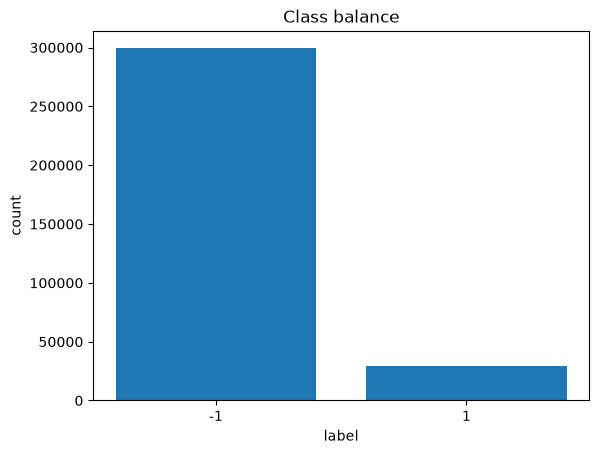

In [21]:
# TODO: class balance
labels, counts = np.unique(y_train, return_counts=True)
plt.bar(labels.astype(str), counts)
plt.xlabel("label")
plt.ylabel("count")
plt.title("Class balance")
plt.show()

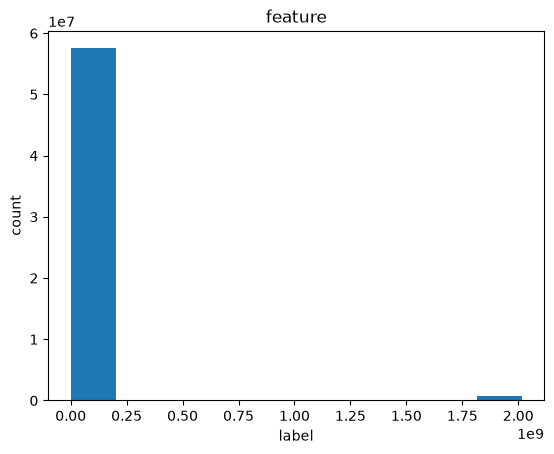

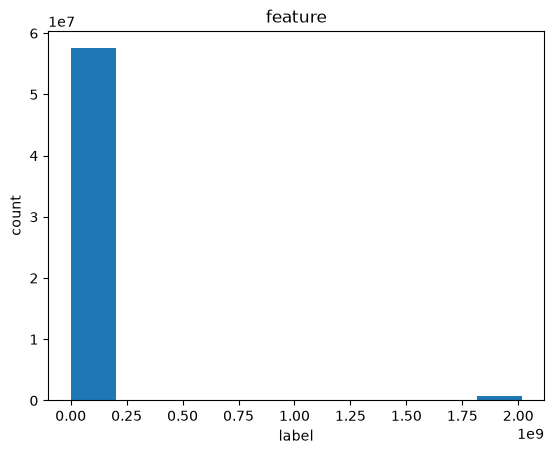

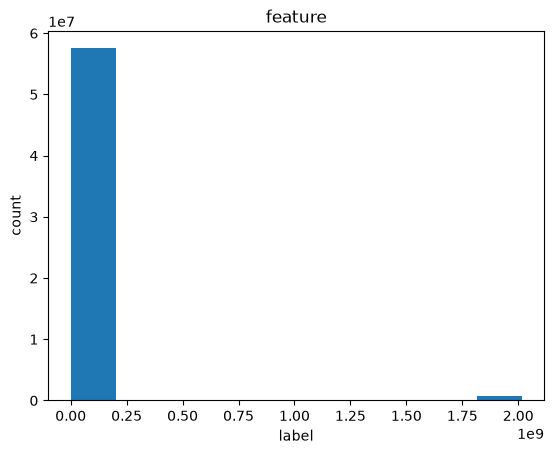

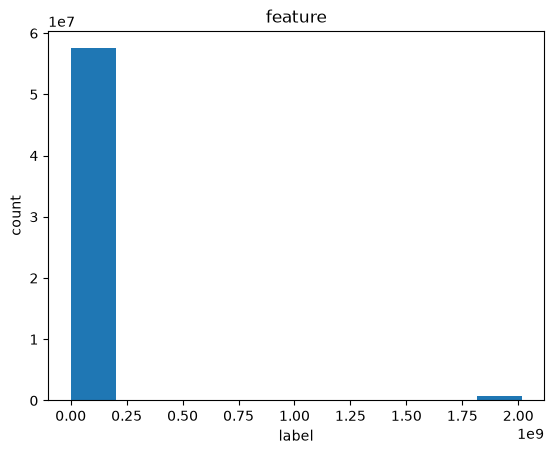

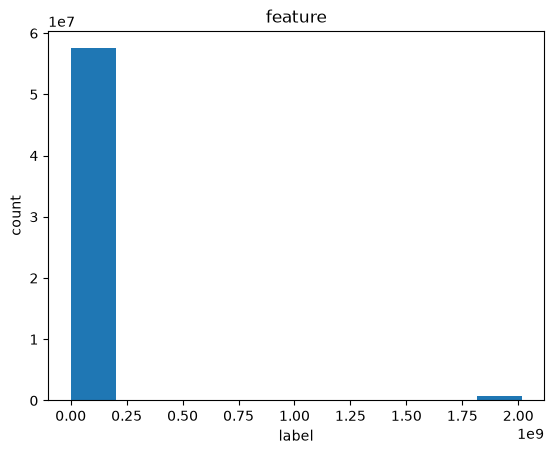

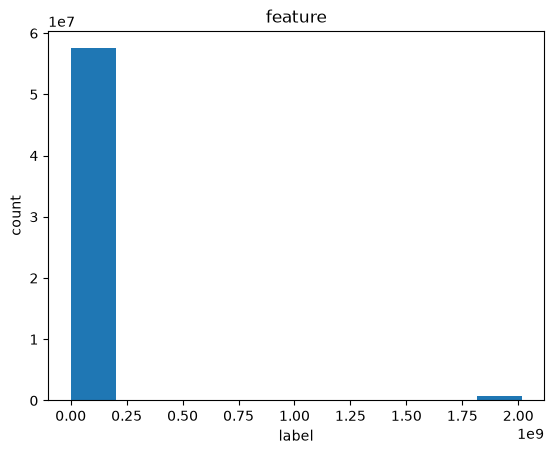

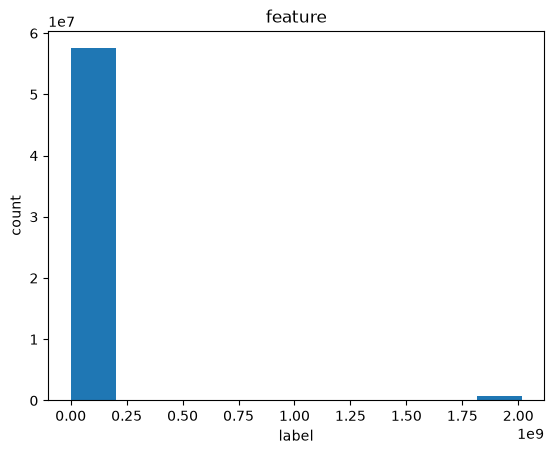

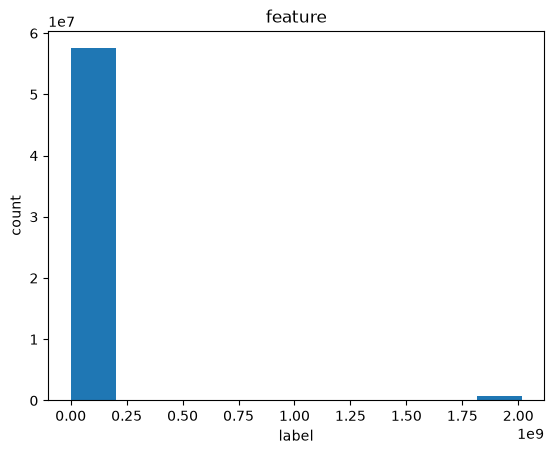

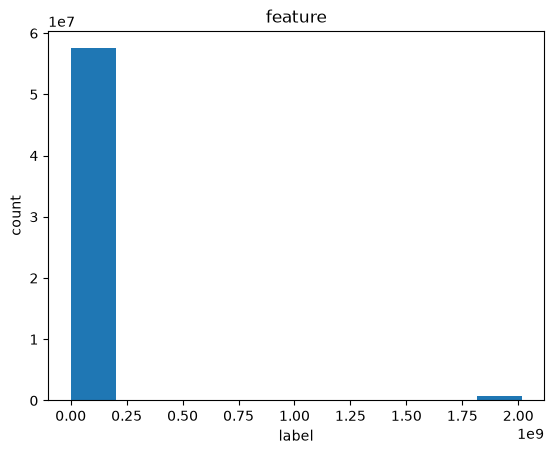

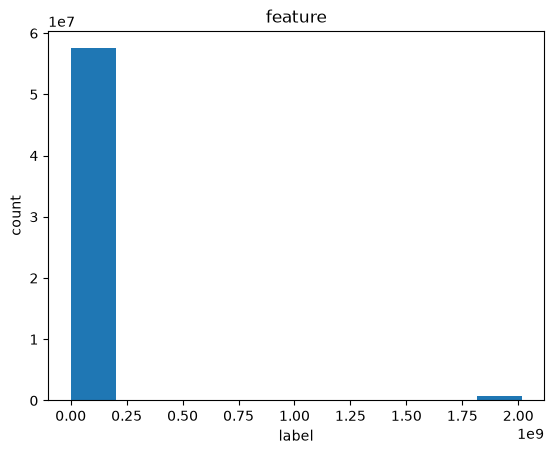

In [29]:
# TODO: missing-value survey, per-feature histograms, correlation checks, etc.
def plot_feature(data):
    plt.hist(data[~np.isnan(data)])

    plt.xlabel("label")
    plt.ylabel("count")
    plt.title("feature")
    plt.show()

for feature in range(0, 10):
    plot_feature(x_train[feature:])


## 3. Feature processing

Cleaning, imputation, scaling, encoding, feature construction. Must be applied identically
to `x_train` and `x_test` — factor this into a function so `run.py` can reuse it exactly.

In [ ]:
def build_features(x):
    """Clean + transform raw features into the design matrix used for training."""
    # TODO: handle missing/sentinel values, scale, engineer features, add bias column
    raise NotImplementedError


def build_labels(y):
    """Map raw labels to whatever convention the chosen method expects.

    Note: helpers.create_csv_submission expects final predictions in {-1, 1},
    but logistic_regression / reg_logistic_regression expect y in {0, 1} during training.
    """
    # TODO
    raise NotImplementedError

In [ ]:
# tx_train = build_features(x_train)
# tx_test = build_features(x_test)
# y_train_processed = build_labels(y_train)

## 4. Train / validation split (local evaluation)

Always estimate test error locally (holdout or k-fold CV) — AIcrowd only allows 5
submissions/day and the competition score must not be your only signal.

In [ ]:
def split_data(y, tx, ratio=0.8, seed=1):
    """Random train/validation split."""
    # TODO: implement (np.random.permutation, slice by ratio)
    raise NotImplementedError


def build_k_indices(y, k_fold, seed=1):
    """Build k-fold row indices for cross-validation."""
    # TODO: implement
    raise NotImplementedError

## 5. Baselines: the 6 required methods

Sanity-check each function in `implementations.py` on the processed data before trying
anything fancier. These are also what the course's grading tests exercise directly.

In [ ]:
# Example calls once build_features / split_data are implemented:
#
# w, loss = impl.least_squares(y_tr, tx_tr)
# w, loss = impl.ridge_regression(y_tr, tx_tr, lambda_=1e-3)
# w, loss = impl.mean_squared_error_gd(y_tr, tx_tr, initial_w, max_iters=100, gamma=0.1)
# w, loss = impl.mean_squared_error_sgd(y_tr, tx_tr, initial_w, max_iters=1000, gamma=0.01)
# w, loss = impl.logistic_regression(y_tr01, tx_tr, initial_w, max_iters=100, gamma=0.1)
# w, loss = impl.reg_logistic_regression(y_tr01, tx_tr, lambda_=1e-3, initial_w=initial_w, max_iters=100, gamma=0.1)

## 6. Model selection

Hyperparameter search (e.g. lambda_, gamma) via cross-validation. Keep track of results for
the ablation study required in the report.

In [ ]:
# TODO: cross-validation loop over hyperparameters, record train/val loss and a
# classification metric (accuracy / F1 — the labels are imbalanced).

## 7. Final model + submission

This should mirror exactly what `../run.py` does, so the two stay reproducible together.

In [ ]:
# w, loss = impl.ridge_regression(y_train_processed, tx_train, lambda_=...)
# y_pred = tx_test @ w
# y_pred = np.where(y_pred >= 0, 1, -1)
# create_csv_submission(test_ids, y_pred, "../submission.csv")